# AI-асистент аналітика

**Принцип:** Pandas рахує, Gemini інтерпретує. LLM не отримує сирих даних і не рахує числа: він бачить
готові факти з ID, а код перевіряє, що кожне його твердження на них спирається.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from analyst.eda import load_csv, auto_eda, plot_distributions
from analyst.hypotheses import suggest_hypotheses
from analyst.nl2pandas import ask_data
from analyst.anomaly import explain_change
from analyst.summary import executive_summary, to_markdown
from analyst.display import show_eda, show_hypotheses, show_explanation

df = load_csv("data/olist_clean.csv")
print(df.shape, "| унікальних замовлень:", df["order_id"].nunique())
df.head(3).T

(111752, 41) | унікальних замовлень: 97905


,0,1,2
order_id,e481f51cbdc54678b7cc49136f2d6af7,53cdb2fc8bc7dce0b6741e2150273451,47770eb9100c2d0c44946d9cf07ec65d
customer_id,9ef432eb6251297304e76186b10a928d,b0830fb4747a6c6d20dea0b8c802d7ef,41ce2a54c0b03bf3443c3d931a367089
order_status,delivered,delivered,delivered
order_purchase_timestamp,2017-10-02 10:56:33,2018-07-24 20:41:37,2018-08-08 08:38:49
order_delivered_carrier_date,2017-10-04 19:55:00,2018-07-26 14:31:00,2018-08-08 13:50:00
order_delivered_customer_date,2017-10-10 21:25:13,2018-08-07 15:27:45,2018-08-17 18:06:29
order_estimated_delivery_date,2017-10-18 00:00:00,2018-08-13 00:00:00,2018-09-04 00:00:00
order_item_id,1,1,1
product_id,87285b34884572647811a353c7ac498a,595fac2a385ac33a80bd5114aec74eb8,aa4383b373c6aca5d8797843e5594415
seller_id,3504c0cb71d7fa48d967e0e4c94d59d9,289cdb325fb7e7f891c38608bf9e0962,4869f7a5dfa277a7dca6462dcf3b52b2


## Автоматичний EDA

Датасет: 111,752 рядків × 41 колонок; повних дублікатів: 0
Оцінка якості даних: 8/10

Колонки:
  колонка                       тип           пропуски %    унік.  розподіл
  order_id                      str                  0.0    97905  ідентифікатор
  customer_id                   str                  0.0    97905  ідентифікатор
  order_status                  str                  0.0        5  delivered 98.32%, shipped 1.05%, processing 0.32%
  order_purchase_timestamp      datetime64[u         0.0    97353  2017-01-05 … 2018-08-29
  order_delivered_carrier_date  datetime64[u        0.79    80617  2017-01-06 … 2018-09-11
  order_delivered_customer_date datetime64[u        1.68    95393  2017-01-11 … 2018-10-17
  order_estimated_delivery_date datetime64[u         0.0      420  2017-02-01 … 2018-10-25
  order_item_id                 int64                0.0       21  min=1.0, медіана=1.0, max=21.0
  product_id                    str                  0.0    32578  ідентифікатор
  selle

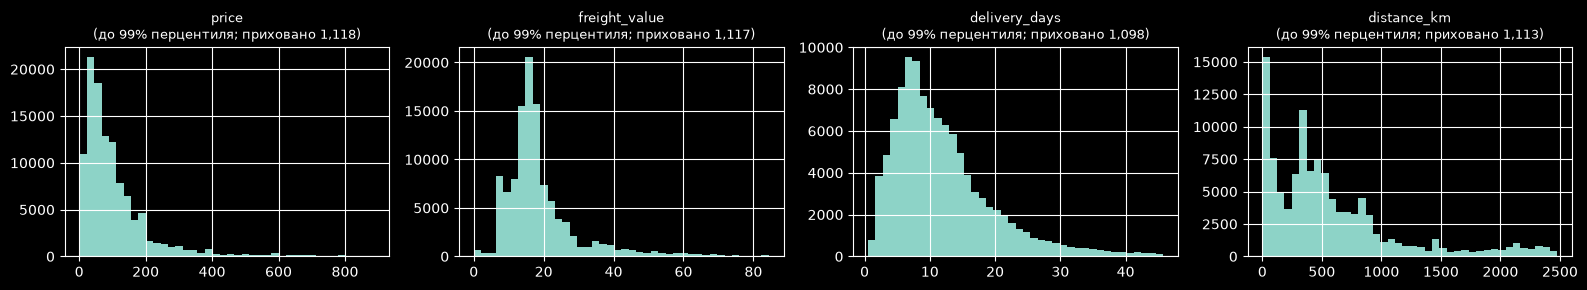

In [2]:
facts, report = auto_eda(df)
show_eda(facts, report)
plot_distributions(df[["price", "freight_value", "delivery_days", "distance_km"]])

## Генерація гіпотез
Колонки метрики виключаю: інакше гіпотези будуть тривіальними
або з оберненою причинністю.

In [3]:
LEAKY = ["delay_days", "delivery_days", "review_score", "has_review_comment",
         "customer_lat", "customer_lng", "seller_lat", "seller_lng"]
facts_h, hyps = suggest_hypotheses(df, metric="is_late", date_col="purchase_date", exclude=LEAKY)
show_hypotheses(facts_h, hyps)


1. [пріоритет 1] Замовлення, оформлені у лютому та березні 2018 року, мають вищий показник затримки доставки порівняно з іншими періодами.
   Обґрунтування: Факти F1 та F2 показують значне зростання is_late у 2018-03 та 2018-02 з високими значеннями z-статистики (+27.8 та +18.6 відповідно), що вказує на часові аномалії.
   F1: purchase_month=2018-03: середнє is_late = 0.2047 (n=8017), +158% відносно загального 0.0793, z=+27.8
   F2: purchase_month=2018-02: середнє is_late = 0.1574 (n=7518), +99% відносно загального 0.0793, z=+18.6
   Як перевірити: Згрупувати дані за purchase_month та порахувати середнє значення is_late і кількість замовлень n.

2. [пріоритет 2] Доставка замовлень до штату RJ частіше супроводжується затримками, тоді як доставка у штат SP має нижчий рівень запізнень.
   Обґрунтування: Факти F3 та F4 демонструють суттєві відхилення is_late для клієнтів у штатах RJ (+64%, z=+18.0) та SP (-27%, z=-19.9).
   F3: customer_state=RJ: середнє is_late = 0.1302 (n=14097), +64% в

## Natural Language - Pandas
Код завжди видимий. Питання №2 перевіряє пастку, один рядок = позиція замовлення, тож замовлення треба
рахувати через nunique. Питання №4 нелогічне, очікуємо відмову з поясненням.

In [4]:
OLIST_CONTEXT = """Один рядок = одна позиція замовлення (не замовлення): кількість замовлень рахуй через order_id.nunique().
revenue = price + freight_value. is_late: 1 — запізнилось, 0 — вчасно, NaN — не доставлено (не рахуй NaN як 0).
review_score — оцінка 1–5 (усереднена по замовленню). Дані: 2017-01 … 2018-08, статуси canceled/unavailable виключено."""

questions = [
    "Покажи топ-5 штатів клієнтів за виручкою",
    "Скільки унікальних замовлень було у листопаді 2017?",
    "Яка частка запізнених доставок за способами оплати?",
    "Який настрій у клієнтів?",
]
for q in questions:
    r = ask_data(df, q, context=OLIST_CONTEXT)
    print(q)
    if r["ok"]:
        print(r["explanation"], f"(спроб: {r['attempts']})\n\n{r['code']}\n")
        display(r["result"])
    else:
        print(r["message"])

Покажи топ-5 штатів клієнтів за виручкою
Код групує дані за штатом клієнтів (customer_state), підсумовує виручку (revenue) для кожного штату, сортує за спаданням і вибирає топ-5. (спроб: 1)

result = df.groupby('customer_state')['revenue'].sum().reset_index().sort_values(by='revenue', ascending=False).head(5)



,customer_state,revenue
25,SP,5863232.66
18,RJ,2105549.64
10,MG,1837646.07
22,RS,873634.76
17,PR,791701.89


Скільки унікальних замовлень було у листопаді 2017?
Код фільтрує датафрейм за місяцем покупки '2017-11' і рахує кількість унікальних замовлень за допомогою order_id.nunique(), згідно з правилом для підрахунку замовлень. (спроб: 1)

result = df[df['purchase_month'] == '2017-11']['order_id'].nunique()



7421

Яка частка запізнених доставок за способами оплати?
Обчислено частку запізнених доставок у відсотках для кожного способу оплати через .mean() для колонки is_late (ігноруючи NaN), помножено на 100 та округлено до двох знаків. (спроб: 1)

result = df.groupby('payment_type')['is_late'].mean().mul(100).round(2).reset_index().rename(columns={'is_late': 'is_late_pct'})



,payment_type,is_late_pct
0,boleto,8.63
1,credit_card,7.77
2,debit_card,8.25
3,voucher,6.92


Який настрій у клієнтів?
У датафреймі немає прямої колонки для настрою клієнтів, але є оцінки відгуків review_score. Спробуйте переформулювати питання: 'Яка середня оцінка review_score за місяцями?'


## Пояснення аномалій
Внески сегментів рахує Pandas; LLM лише формулює гіпотези причин із посиланням на факти.

**Кейс 1.** Листопад 2017 (чорна п'ятниця): стрибок частки запізнень відносно жовтня.

In [5]:
facts_a, expl_a = explain_change(
    df, "purchase_date", "is_late", "mean",
    before=("2017-10-01", "2017-10-31"), after=("2017-11-01", "2017-11-30"),
    dims=["seller_state", "customer_state", "category_grouped"],
    id_col="order_id")
show_explanation(facts_a, expl_a)

Зростання середнього значення is_late з 5.06% до 13.83% (+8.77 п.п., +173.2%) у періоді 2017-11-01…2017-11-30 порівняно з 2017-10-01…2017-10-31.

is_late (mean): 0.0506 у періоді 2017-10-01…2017-10-31 → 0.1383 у періоді 2017-11-01…2017-11-30; зміна +0.0877 (+173.2%). У відсотках: 5.06% → 13.83%, +8.77 п.п. Унікальних order_id (усі в періоді): 4547 → 7421; з відомим is_late: 4478 → 7288; позицій (рядків) з відомим is_late: 5214 → 8474. Загальна зміна: z=+18.2 (статистично значуща).

Головні драйвери: Основними драйверами зміни є сегмент постачальників seller_state = SP, клієнтський регіон customer_state = RJ та комбінація SP × RJ, а також товарні категорії bed_bath_table та furniture_decor.

1. [впевненість (за z-тестом): high] Зміна є системною, оскільки після виключення основного сегмента seller_state = SP лишається 64% від початкової зміни, а також спостерігається зростання в інших регіонах та категоріях.
   F1: Розріз seller_state = SP: внесок +0.0721 (+82% від загальної зміни); над

In [6]:
b = df[df.purchase_month == "2017-10"]["is_late"].mean()
a = df[df.purchase_month == "2017-11"]["is_late"].mean()
print(f"Перевірка: {b:.4f} - {a:.4f}"); print(facts_a["F0"])

Перевірка: 0.0506 - 0.1383
is_late (mean): 0.0506 у періоді 2017-10-01…2017-10-31 → 0.1383 у періоді 2017-11-01…2017-11-30; зміна +0.0877 (+173.2%). У відсотках: 5.06% → 13.83%, +8.77 п.п. Унікальних order_id (усі в періоді): 4547 → 7421; з відомим is_late: 4478 → 7288; позицій (рядків) з відомим is_late: 5214 → 8474. Загальна зміна: z=+18.2 (статистично значуща).


**Кейс 2.** Січень-березень 2018: частка запізнень зросла з 6.54% до 20.47%.

In [7]:
facts_b, expl_b = explain_change(
    df, "purchase_date", "is_late", "mean",
    before=("2018-01-01", "2018-01-31"), after=("2018-03-01", "2018-03-31"),
    dims=["customer_state", "seller_state", "category_grouped"],
    id_col="order_id")
show_explanation(facts_b, expl_b)

Зростання частки запізнень is_late з 6.54% до 20.47% (+13.92 п.п.) у періоді 2018-03-01…2018-03-31 порівняно з 2018-01-01…2018-01-31

is_late (mean): 0.0654 у періоді 2018-01-01…2018-01-31 → 0.2047 у періоді 2018-03-01…2018-03-31; зміна +0.1392 (+212.8%). У відсотках: 6.54% → 20.47%, +13.92 п.п. Унікальних order_id (усі в періоді): 7187 → 7168; з відомим is_late: 7069 → 7003; позицій (рядків) з відомим is_late: 8037 → 8017. Загальна зміна: z=+26.4 (статистично значуща).

Головні драйвери: Основними драйверами росту є специфічні комбінації регіонів покупців і продавців, зокрема напрямки за участі seller_state = SP та customer_state = RJ або MG, а також окремі категорії товарів

1. [впевненість (за z-тестом): high] Зростання частки запізнень зумовлене системними чинниками, що охоплюють багато сегментів, оскільки після виключення seller_state = SP зберігається 67% початкової зміни
   F4: Розріз seller_state = SP: внесок +0.1160 (+83% від загальної зміни); надлишковий внесок понад пропорці

**Кейс 3.** Синтетичні дані з відомою підкинутою причиною:
з 16.10.2026 конверсія в сегменті paid_social × android падає у 5 разів.
Інструмент має знайти саме її (python generate_synthetic.py створює файл).

In [8]:
syn = load_csv("data/synthetic_sessions.csv")
facts_s, expl_s = explain_change(
    syn, "date", "converted", "mean",
    before=("2026-10-02", "2026-10-15"), after=("2026-10-16", "2026-10-29"),
    dims=["channel", "platform", "country"],
    id_col="session_id")
show_explanation(facts_s, expl_s)

Конверсія (converted) знизилася з 6.44% до 6.29% (-0.14 п.п., або -2.2%), проте загальна зміна перебуває в межах випадкового шуму (z=-0.6).

converted (mean): 0.0644 у періоді 2026-10-02…2026-10-15 → 0.0629 у періоді 2026-10-16…2026-10-29; зміна -0.0014 (-2.2%). У відсотках: 6.44% → 6.29%, -0.14 п.п. Унікальних session_id (усі в періоді): 23431 → 23288; з відомим converted: 23431 → 23288; позицій (рядків) з відомим converted: 23466 → 23305. Загальна зміна: z=-0.6 (в межах випадкового шуму).

Головні драйвери: Основними драйверами зниження є сегменти channel = paid_social, platform = android, а також їх перетин paid_social × android.

1. [впевненість (за z-тестом): medium] Зниження конверсії головним чином зумовлене сегментом paid_social, де середня конверсія впала з 4.67% до 3.80% (z=-2.1).
   F1: Розріз channel = paid_social: внесок -0.0018 (+123% від загальної зміни); надлишковий внесок понад пропорційну частку -0.0015 (+103%); середнє в сегменті 0.0467 → 0.0380; частка трафіку 20.1%

## Executive summary

In [9]:
from analyst.summary import executive_summary, to_markdown, business_metrics
from IPython.display import Markdown

biz = business_metrics(df, "purchase_date",
                       before=("2017-10-01", "2017-10-31"), after=("2017-11-01", "2017-11-30"),
                       id_col="order_id", revenue_col="revenue", score_col="review_score")
print(biz)
summary = executive_summary(facts_a, audience="CEO", extra=biz)
Markdown(to_markdown(summary))

Унікальних замовлень: 4547 → 7421 (+63.2%)
Виручка: 764756 → 1172192 (+53.3%)
Середня оцінка клієнтів: 4.080 → 3.858 (-5.4%)


## Різке зростання затримок доставки у листопаді 2017 року

**Що сталося:** У періоді 2017-10-01…2017-10-31 та 2017-11-01…2017-11-30 частка запізнень is_late зросла з 5.06% до 13.83% (+8.77 п.п., статистично значуща зміна z=+18.2). Кількість унікальних замовлень змінилася з 4547 до 7421, а виручка зросла з 764756 до 1172192. Найбільший надлишковий внесок зафіксовано у продавців із штату SP (+10%, середнє 5.92% → 15.89%), покупців зі штату RJ (+17%, середнє 7.25% → 26.86%) та категорії bed_bath_table (+10%, середнє 4.80% → 21.02%). Зміна носить системний характер, оскільки без сегмента seller_state = SP лишається 64% від початкової зміни (+0.0563). Піки затримок припали на кінець місяця: 2017-11-25 (22.85%), 2017-11-26 (21.11%), 2017-11-27 (20.26%). Середня оцінка клієнтів знизилася з 4.080 до 3.858 (-5.4%).

**Чому це важливо:** Зростання частки запізнень майже утричі та падіння середньої оцінки клієнтів до 3.858 ймовірно свідчать про логістичні проблеми у піковий період (наприклад, Black Friday), що може негативно вплинути на повторні замовлення.

**Що робити:**
- Провести аудит логістичних партнерів та маршрутів для напрямку seller_state = SP та customer_state = RJ, де зафіксовано найбільші надлишкові внески затримок (+10% та +17%).
- Дослідити операційні процеси обробки замовлень у категорії bed_bath_table, де середнє запізнень зросло до 21.02% з надлишковим внеском +10%.

*Обмеження:* Дані охоплюють лише два місяці (лютий виключено з контексту), причино-наслідкові зв'язки не доведені повністю, а зміни у певних сегментах (наприклад, seller_state = SC з z=+1.0) знаходяться в межах випадкового шуму.

## Висновки

Числа, які рахував Pandas, збіглися з незалежною перевіркою:
- 7421 унікальне замовлення у листопаді 2017 (nunique);
- 4547 - 7421 у F0 і в business_metrics;
- частки запізнень за способами оплати (mean(), NaN ігнорується);
- зміна частки запізнень у кейсах 1 і 2 (5.06% - 13.83% та 6.54% - 20.47%).

На синтетичних даних інструмент знайшов підкинутий сегмент paid_social × android
і визнав загальну зміну шумом. На Olist він показав, що листопадовий сплеск
запізнень 2017 року системний і сконцентрований 25–27 листопада.

Де помилявся LLM і що виправлено:
- Рахував позиції замість замовлень. F0 тепер підраховує унікальні order_id до відкидання рядків без
  is_late, а числа з відомим is_late подані окремо й підписані.
- Видавав великі сегменти за причину. До LLM і до summary передається лише надлишковий внесок
  понад пропорційну частку.
- Називав шум причиною. Додано z-тест. Впевненість рахує код, а коли z-тесту немає, показується n/a, а не значення від LLM.
- Для частки запізнень писав (x == 1).mean(), що рахує NaN як вчасно. У схему даних додано правило
  .mean() для 0/1-колонок із NaN, результат збігається з перерахунком.
- Вигадував сезонність, віддалені штати і транспортні компанії, додано заборони й список доступних колонок.
- Позначав IQR-викиди в координатах і лічильниках як проблему даних, такі колонки виключено з аналізу викидів,
  а severity тепер визначається за правилом, а не моделлю.

Що лишилось неідеальним:
- Кейс 3. Окрім справжньої причини (paid_social × android, high), LLM видав ще три причини з рівнем
  medium: paid_social, android і android × PL. Перші дві просіли лише тому,
  що містять підкинутий перетин, а третя — шум, сегментів перевіряється кілька десятків.
- Впевненість «high» вимірює значущість окремого сегмента, а не обґрунтованість тези про системність.
- Інколи summary або пояснення виходять за дані, згадують логістичних партнерів, «Black Friday» чи періоди,
  яких немає у фактах. Вони подані як припущення, але їх треба перевіряти.
- Гіпотези частково дублюють одна одну (price і revenue дають ідентичні факти; штат, same_state,
  відстань і фрахт взаємопов'язані).
- review_score (усереднена порядкова шкала) потрапляє в викиди за IQR, а штраф за викиди майже завжди
  впирається в максимум, тож оцінка якості малоінформативна.
- Z-тести вважають рядки незалежними, хоча позиції одного замовлення залежні, тому значущість дещо завищена.
Усі причини є гіпотезами для перевірки, а не доведеною причинністю. Повна історія ітерацій промптів у prompts.md.